# Class distribution slide figure

Bar chart of annotated instances per species in the re-annotated dataset (1,462 frames, 4,098 fish, 40 species),
on a **linear** scale so the imbalance is obvious on a slide. Callouts match the talk:
Yellow Tang ≈ 27%, Convict Tang < 1%, top 3 ≈ 63%, half the species < 20 instances.

Settings to edit:
- `THEME`: `'light'` or `'dark'`
- `LABELS`: `'all'` names every species; `'key'` names only the top 3 and the focus species (cleaner on a slide)
- `LOG_SCALE`: `True` gives the report-style log axis
- Text of the callouts and title in the plotting cell

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

THEME = 'light'      # 'light' or 'dark'
LABELS = 'all'       # 'all' or 'key'
LOG_SCALE = False
SAVE = True
DPI = 150

## Data: annotated instances per species (corrected CVAT labels, frames 1000–2461)

In [2]:
COUNTS = {
    'Yellow Tang': 1119, 'Brown Surgeonfish': 875, 'Orangeband Surgeonfish': 568, 'Blackfin Chromis': 310,
    'Goldring Surgeonfish': 252, 'Moorish Idol': 143, 'Raccoon Butterflyfish': 101, 'Ornate Butterflyfish': 99,
    'Forcepsfish': 93, 'Orangespine Unicornfish': 77, 'Acanthuridae': 56, 'Lowfin Chub': 41, 'Convict Tang': 33,
    'Black Triggerfish': 30, 'Redlip Parrotfish - Male': 30, 'Redlip Parrotfish - Female': 27, 'Lei Triggerfish': 25,
    'Fourspot Butterflyfish': 22, 'Doublebar Goatfish': 21, 'Multiband Butterflyfish': 21,
    'Bullethead Parrotfish - Female': 18, 'Hawaiian Whitespotted Toby': 15, 'Bullethead Parrotfish': 14,
    'Whitebar Surgeonfish': 13, 'Whitecheek Surgeonfish': 11, 'Whitespotted Surgeonfish': 11, 'Chinese Trumpetfish': 9,
    'Blue Goatfish': 9, 'Bluefin Trevally': 8, 'Saddle Wrasse - Male': 8, 'Ringtail Surgeonfish': 8,
    'Lined Butterflyfish': 7, 'Indo-Pacific Sergeant': 6, 'Chevron Tang': 5, 'Highfin Chub': 4,
    'Longnose Butterflyfish': 4, 'Manybar Goatfish': 2, 'Hawaiian Cleaner Wrasse': 1, 'Pyramid Butterflyfish': 1,
    'Palenose Parrotfish - Male': 1}
FOCUS = ['Forcepsfish', 'Orangespine Unicornfish', 'Convict Tang']

names = list(COUNTS); vals = np.array([COUNTS[n] for n in names]); total = vals.sum()
print(f'{total:,} fish, {len(names)} species')
print(f'Yellow Tang {COUNTS["Yellow Tang"] / total:.1%}, Convict Tang {COUNTS["Convict Tang"] / total:.1%}, '
      f'top 3 {vals[:3].sum() / total:.1%}, species < 20 instances: {(vals < 20).sum()}')

4,098 fish, 40 species
Yellow Tang 27.3%, Convict Tang 0.8%, top 3 62.5%, species < 20 instances: 20


## Style

In [3]:
THEMES = {
    'light': dict(bg='#ffffff', ink='#0b0b0b', ink2='#52514e', grid='#e1e0d9', axis='#898781',
                  blue='#2a78d6', orange='#eb6834', shade='#efeee9'),
    'dark':  dict(bg='#0f1b2d', ink='#f0efec', ink2='#c3c2b7', grid='#26354b', axis='#6d7a8e',
                  blue='#4a90e8', orange='#e2683a', shade='#18283f'),
}
T = THEMES[THEME]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 16, 'text.color': T['ink'],
                     'axes.labelcolor': T['ink2'], 'axes.edgecolor': T['axis'], 'xtick.color': T['ink2'],
                     'ytick.color': T['ink2'], 'axes.facecolor': T['bg'], 'figure.facecolor': T['bg'],
                     'savefig.facecolor': T['bg'], 'axes.titlesize': 20, 'axes.titleweight': 'bold',
                     'axes.titlecolor': T['ink'], 'axes.titlelocation': 'left', 'axes.titlepad': 14,
                     'legend.frameon': False, 'legend.fontsize': 15})

## Plot

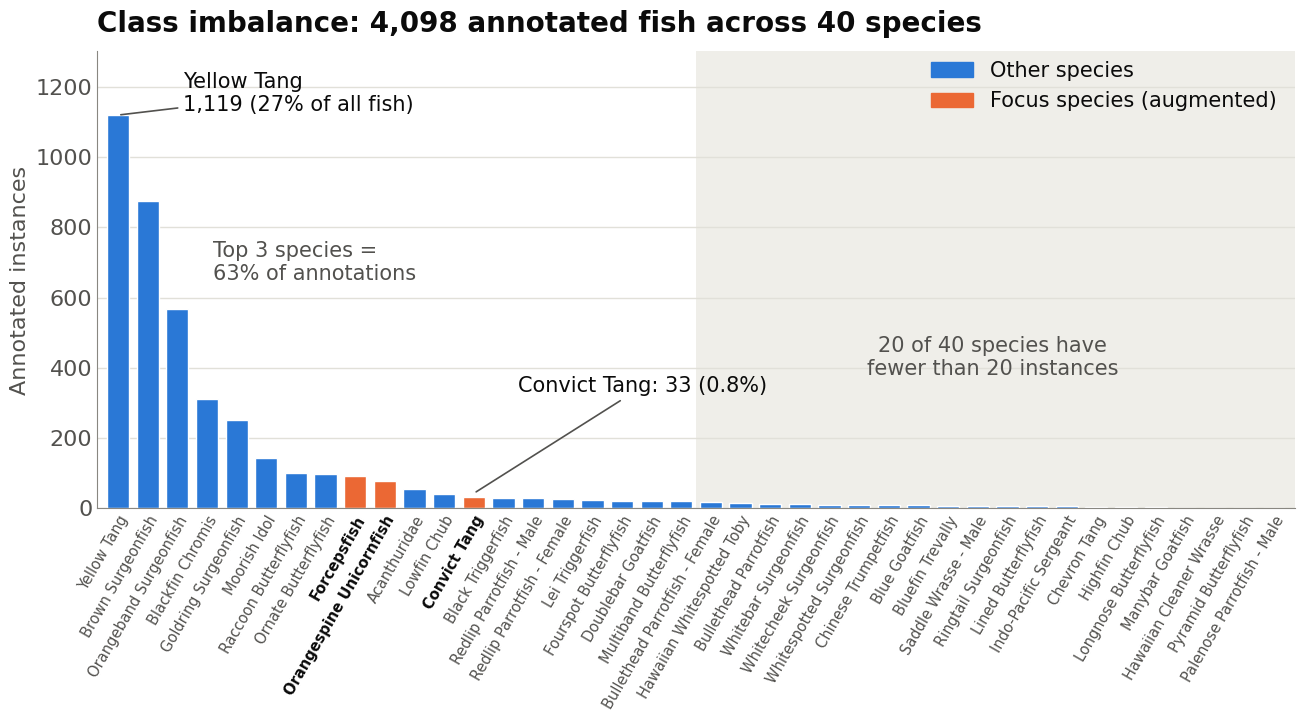

In [4]:
fig, ax = plt.subplots(figsize=(13.33, 7.5))
x = np.arange(len(names))
ax.bar(x, vals, color=[T['orange'] if n in FOCUS else T['blue'] for n in names], width=0.75,
       edgecolor=T['bg'], lw=1)

# x labels
if LABELS == 'all':
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=60, ha='right', rotation_mode='anchor', fontsize=10.5)
else:  # 'key': names written on the top 3 bars and above the focus-species bars
    ax.set_xticks([]); ax.set_xlabel('Species, sorted by number of annotated instances')
    for i in range(1, 3):  # Yellow Tang is named by its callout
        ax.text(i, vals[i] - 25, names[i], rotation=90, ha='center', va='top', fontsize=13, color='white',
                fontweight='bold')
    for n in FOCUS:
        i = names.index(n)
        if n != 'Convict Tang':  # Convict Tang is named by its callout
            ax.text(i, vals[i] + 20, n, rotation=90, ha='center', va='bottom', fontsize=13, fontweight='bold',
                    color=T['ink'])
for t in ax.get_xticklabels():
    if t.get_text() in FOCUS: t.set_color(T['ink']); t.set_fontweight('bold')

# axes
if LOG_SCALE:
    ax.set_yscale('log'); ax.set_ylim(0.8, 3000); ax.set_ylabel('Annotated instances (log scale)')
else:
    ax.set_ylim(0, 1300); ax.set_ylabel('Annotated instances')
ax.set_xlim(-0.7, len(names) - 0.3)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(axis='y', color=T['grid'], lw=1); ax.set_axisbelow(True); ax.tick_params(length=0)

# shaded tail: species with fewer than 20 instances
first = int(np.argmax(vals < 20)); k = int((vals < 20).sum())
ax.axvspan(first - 0.5, len(names) - 0.3, color=T['shade'], lw=0, zorder=0)
ax.text((first + len(names)) / 2 - 0.5, 380 if not LOG_SCALE else 60,
        f'{k} of {len(names)} species have\nfewer than 20 instances', ha='center', fontsize=15, color=T['ink2'])

# callouts (edit text / positions here)
yt = COUNTS['Yellow Tang']
ax.annotate(f'Yellow Tang\n{yt:,} ({yt / total:.0%} of all fish)', (0, yt), (2.2, 1180 if not LOG_SCALE else 1800),
            fontsize=15, va='center', arrowprops=dict(arrowstyle='-', color=T['ink2'], lw=1.2))
ax.text(3.2, 700 if not LOG_SCALE else 400, f'Top 3 species =\n{vals[:3].sum() / total:.0%} of annotations',
        fontsize=15, color=T['ink2'], va='center')
i = names.index('Convict Tang'); ct = COUNTS['Convict Tang']
ax.annotate(f'Convict Tang: {ct} ({ct / total:.1%})', (i, ct + 10), (i + 1.5, 330 if not LOG_SCALE else 150),
            fontsize=15, arrowprops=dict(arrowstyle='-', color=T['ink2'], lw=1.2))

ax.legend(handles=[Rectangle((0, 0), 1, 1, color=T['blue']), Rectangle((0, 0), 1, 1, color=T['orange'])],
          labels=['Other species', 'Focus species (augmented)'], loc='upper right', bbox_to_anchor=(1, 1.02))
ax.set_title(f'Class imbalance: {total:,} annotated fish across {len(names)} species')
fig.tight_layout()
if SAVE:
    for ext in ('png', 'pdf'):
        fig.savefig(f'class_imbalance_{THEME}_{LABELS}{"_log" if LOG_SCALE else ""}.{ext}', dpi=DPI)
plt.show()